# Customer Segmentation with RFM Analysis and K-Means Clustering

**Goal:** group customers by purchasing behaviour so that marketing and retention efforts can be targeted at the right people.

Each customer is described by three **RFM** features:

| Feature | Meaning | Better customers have |
|---|---|---|
| **Recency** | Days since the last purchase | Lower values |
| **Frequency** | Number of purchases | Higher values |
| **MonetaryValue** | Total amount spent ($) | Higher values |

**Approach**
1. Load and inspect the data
2. Standardize the RFM features
3. Use the Elbow Method to choose the number of clusters
4. Train a K-Means model and profile each segment
5. Validate the clusters against the existing segment labels
6. Translate the segments into business actions

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from kneed import KneeLocator

DATA_PATH = Path("../data/customer_rfm.csv")
IMAGE_DIR = Path("../images")
OUTPUT_DIR = Path("../outputs")
IMAGE_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

## 2. Load and inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (20, 5)


,CustomerID,Segment,Recency,Frequency,MonetaryValue
0,1,Segment1,10,25,500
1,2,Segment2,5,40,1000
2,3,Segment1,15,10,250
3,4,Segment3,3,60,1500
4,5,Segment2,8,35,800


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   CustomerID     20 non-null     int64
 1   Segment        20 non-null     str  
 2   Recency        20 non-null     int64
 3   Frequency      20 non-null     int64
 4   MonetaryValue  20 non-null     int64
dtypes: int64(4), str(1)
memory usage: 932.0 bytes


In [4]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
CustomerID,20.0,10.5,5.9,1.0,5.8,10.5,15.2,20.0
Recency,20.0,7.4,5.9,1.0,2.8,5.5,10.5,20.0
Frequency,20.0,48.0,24.6,10.0,27.2,47.5,66.2,90.0
MonetaryValue,20.0,1090.0,659.3,250.0,537.5,975.0,1550.0,2400.0


The dataset has 20 customers and no missing values. The three RFM features are on very different scales (Recency: 1–20 days, MonetaryValue: \$250–\$2,400), so they must be standardized before clustering. Otherwise MonetaryValue would dominate the distance calculation.

## 3. Feature selection and scaling

In [5]:
features = ["Recency", "Frequency", "MonetaryValue"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

`CustomerID` is only an identifier and `Segment` is an existing label, so neither is used for training. `Segment` is kept aside to validate the clusters in Section 6.

## 4. Choosing the number of clusters (Elbow Method)

In [6]:
k_values = range(1, 11)
sse = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    sse.append(km.inertia_)

knee = KneeLocator(list(k_values), sse, curve="convex", direction="decreasing")
optimal_k = knee.elbow
print("Optimal number of clusters:", optimal_k)

pd.DataFrame({"K": list(k_values), "SSE (Inertia)": np.round(sse, 2)})

Optimal number of clusters: 3


,K,SSE (Inertia)
0,1,60.00
1,2,18.54
2,3,8.05
3,4,4.28
4,5,2.74
5,6,1.95
6,7,1.53
7,8,1.27
8,9,1.11
9,10,0.82


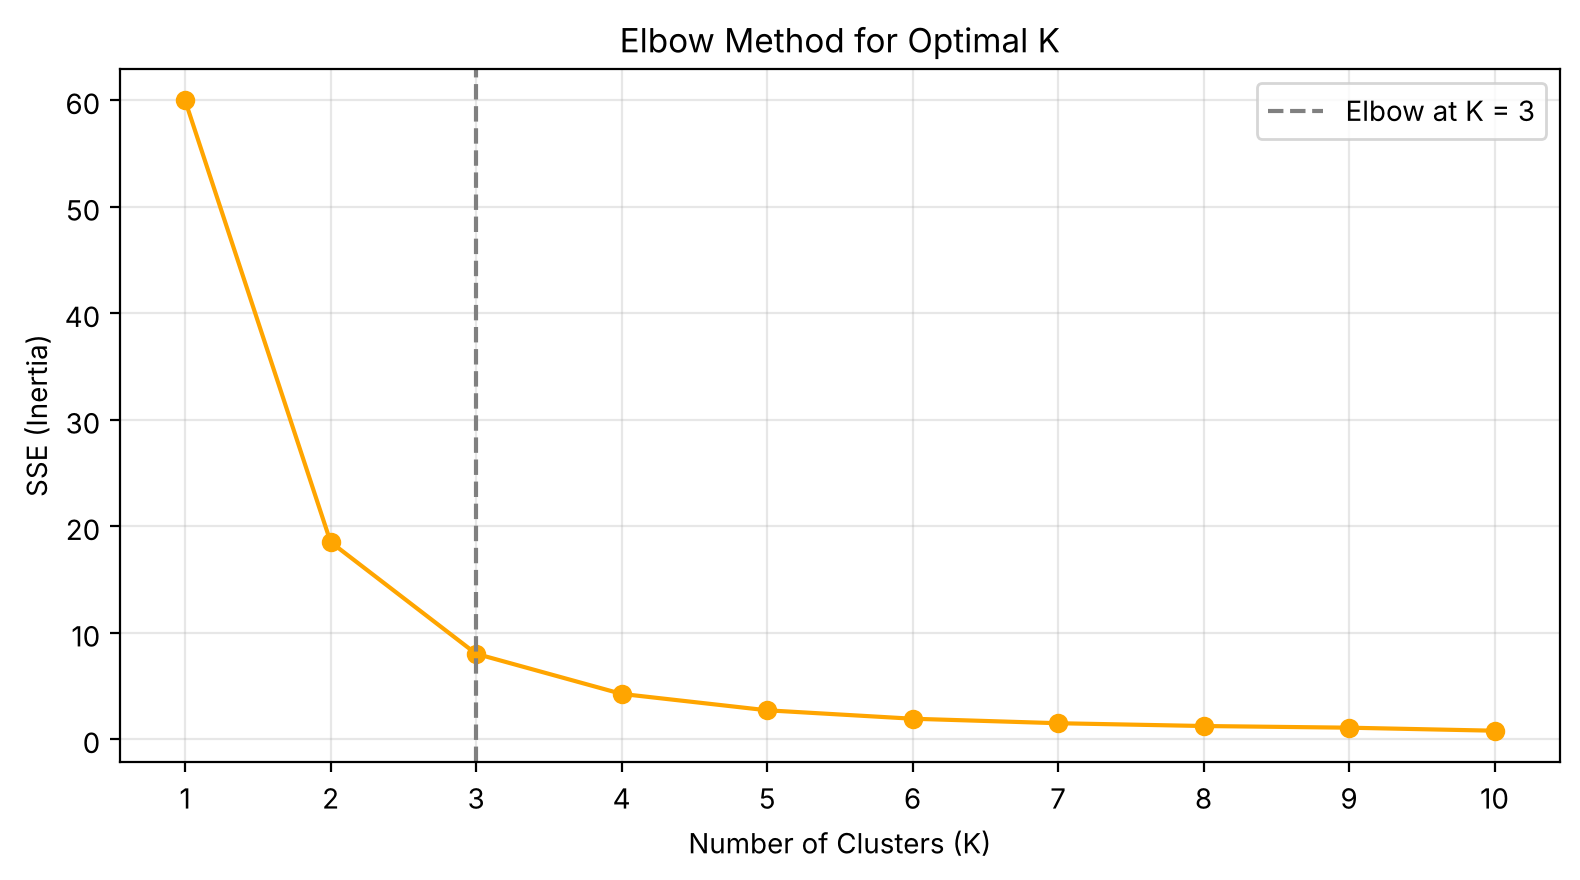

In [7]:
plt.figure(figsize=(8, 4.5))
plt.plot(k_values, sse, "o-", color="orange")
plt.axvline(optimal_k, color="gray", linestyle="--", label=f"Elbow at K = {optimal_k}")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("SSE (Inertia)")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "elbow_method.png", dpi=150)
plt.show()

SSE falls sharply up to K = 3 and flattens afterwards, so **3 clusters** gives the best balance between compact clusters and model simplicity.

## 5. Train the K-Means model and profile the segments

In [8]:
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

profile = df.groupby("Cluster")[features].mean().round(1)
profile["Customers"] = df.groupby("Cluster").size()

order = profile["MonetaryValue"].sort_values().index
names = {order[0]: "At-Risk", order[1]: "Regular", order[2]: "VIP"}
profile["Segment Name"] = profile.index.map(names)
df["Segment Name"] = df["Cluster"].map(names)

profile.sort_values("MonetaryValue", ascending=False)

,Recency,Frequency,MonetaryValue,Customers,Segment Name
Cluster,,,,,
1,1.6,80.0,2020.0,5,VIP
2,5.1,51.2,1093.8,8,Regular
0,14.3,21.4,421.4,7,At-Risk


In [9]:
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                         columns=features).round(1)
centroids["Segment Name"] = centroids.index.map(names)
centroids

,Recency,Frequency,MonetaryValue,Segment Name
0,14.3,21.4,421.4,At-Risk
1,1.6,80.0,2020.0,VIP
2,5.1,51.2,1093.8,Regular


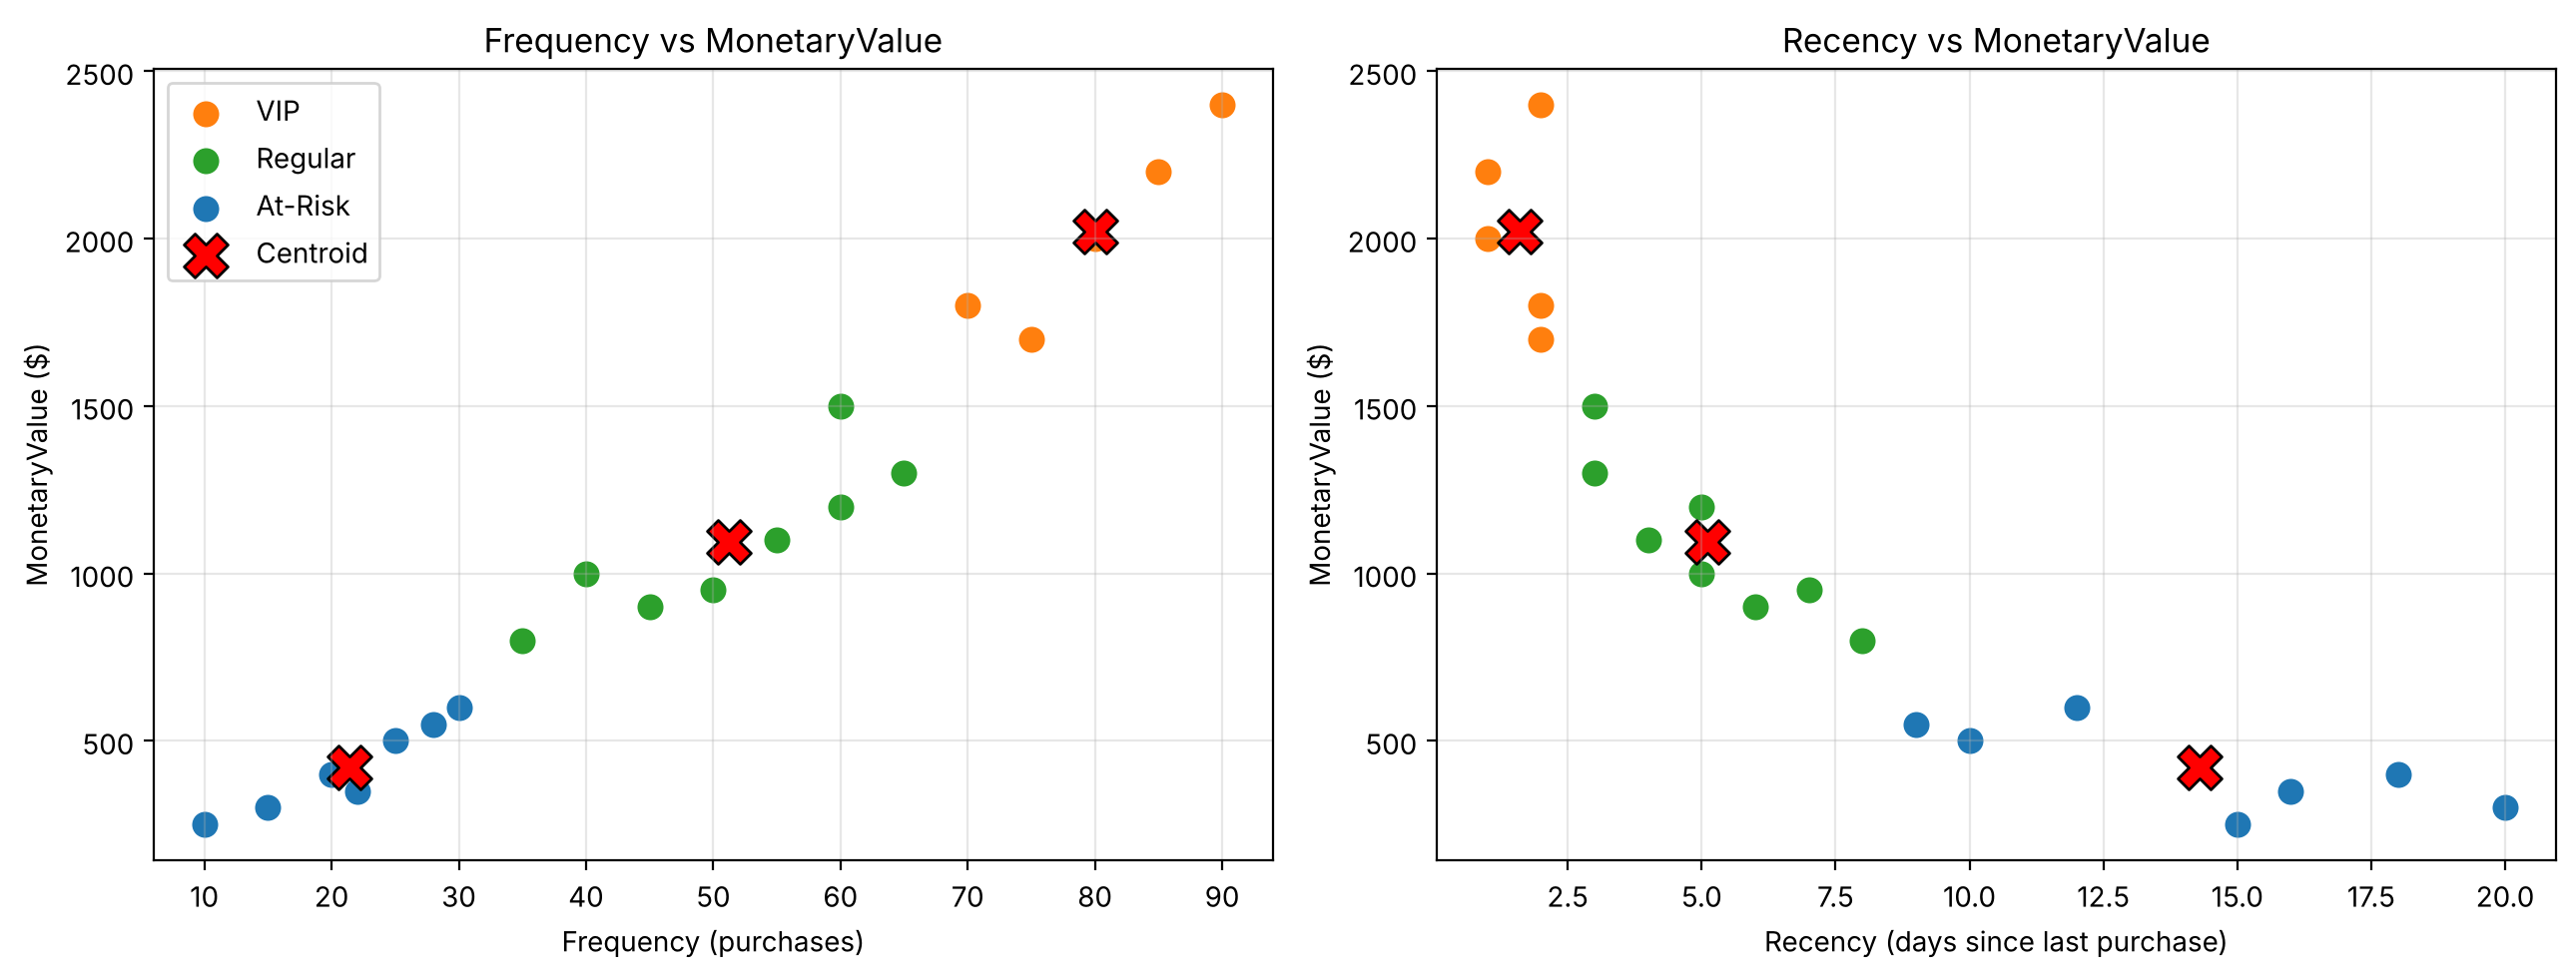

In [10]:
colors = {"VIP": "tab:orange", "Regular": "tab:green", "At-Risk": "tab:blue"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name in ["VIP", "Regular", "At-Risk"]:
    part = df[df["Segment Name"] == name]
    axes[0].scatter(part["Frequency"], part["MonetaryValue"], s=70, color=colors[name], label=name)
    axes[1].scatter(part["Recency"], part["MonetaryValue"], s=70, color=colors[name])

axes[0].scatter(centroids["Frequency"], centroids["MonetaryValue"], marker="X", s=250,
                c="red", edgecolor="k", label="Centroid")
axes[1].scatter(centroids["Recency"], centroids["MonetaryValue"], marker="X", s=250,
                c="red", edgecolor="k")

axes[0].set(xlabel="Frequency (purchases)", ylabel="MonetaryValue ($)", title="Frequency vs MonetaryValue")
axes[1].set(xlabel="Recency (days since last purchase)", ylabel="MonetaryValue ($)", title="Recency vs MonetaryValue")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(IMAGE_DIR / "customer_segments.png", dpi=150)
plt.show()

## 6. Validation against existing segment labels

In [11]:
comparison = pd.crosstab(df["Segment"], df["Segment Name"])
comparison[["At-Risk", "Regular", "VIP"]]

Segment Name,At-Risk,Regular,VIP
Segment,,,
Segment1,7,0,0
Segment2,0,7,0
Segment3,0,1,5


In [12]:
best_match = pd.crosstab(df["Segment"], df["Segment Name"]).idxmax(axis=1)
agreement = (df["Segment Name"] == df["Segment"].map(best_match)).mean()
print(f"Agreement with existing labels: {agreement:.0%}")
df[df["Segment Name"] != df["Segment"].map(best_match)]

Agreement with existing labels: 95%


,CustomerID,Segment,Recency,Frequency,MonetaryValue,Cluster,Segment Name
3,4,Segment3,3,60,1500,2,Regular


The model was trained without the existing labels, yet it reproduces them for **19 of 20 customers (95%)**. The only difference is Customer 4 (60 purchases, \$1,500), whose values sit between the Regular and VIP groups.

## 7. Export results

In [13]:
df[["CustomerID", "Recency", "Frequency", "MonetaryValue", "Cluster", "Segment Name"]] \
    .to_csv(OUTPUT_DIR / "customer_segments.csv", index=False)
print("Saved:", OUTPUT_DIR / "customer_segments.csv")

Saved: ../outputs/customer_segments.csv


## 8. Business insights

| Segment | Avg Recency | Avg Frequency | Avg Spend | Customers | Recommended action |
|---|---|---|---|---|---|
| **VIP** | 1.6 days | 80 | \$2,020 | 5 | Loyalty rewards, early access, personal offers |
| **Regular** | 5.1 days | 51 | \$1,094 | 8 | Upselling and cross-selling to move them to VIP |
| **At-Risk** | 14.3 days | 21 | \$421 | 7 | Win-back campaigns: discounts, reminder emails |

- Frequency and spending are strongly linked: customers who buy more often also spend more.
- The VIP group is only 25% of customers, but its average spend is about **4.8×** that of the At-Risk group.
- Recency is the early-warning signal: At-Risk customers have gone about two weeks without a purchase.